# Olist — анализ покупателей

Шесть вопросов о повторных покупках, сегментах, удержании и ценности покупателя.

**Данные:** слой Gold, SQL-запросы через DuckDB.

**Определения:**

| Понятие | Определение |
|---|---|
| Покупатель | `customer_unique_id` (в Olist `customer_id` создаётся заново для каждого заказа) |
| Покупка | уникальный момент покупки покупателя: несколько заказов в одну секунду — это один чекаут, разбитый по продавцам |
| Повторный покупатель | покупатель с ≥ 2 покупками среди валидных заказов |
| Выручка | сумма `price` товаров валидных заказов, без доставки |

Данные заканчиваются в начале сентября 2018, поэтому у поздних покупателей меньше времени на повторную покупку.
Там, где это важно, сравнение идёт только по покупателям с одинаковым периодом наблюдения.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analytics.db import q
from src.analytics import style as st

st.apply_style()
pd.set_option("display.float_format", lambda v: st.num(v, 2))
pd.set_option("display.max_columns", 30)

## Доля повторных покупок (Repeat Purchase Rate)

**Вопрос:** какая доля покупателей возвращается за второй покупкой?
**Метрика:** RPR = покупатели с ≥ 2 покупками / все покупатели с валидными заказами.

In [2]:
rpr = q("""
    select count(*)                                          as customers,
           sum(is_repeat_customer::int)::bigint              as repeat_customers,
           avg(is_repeat_customer::int)                      as rpr,
           avg((orders_count >= 2)::int)                     as rpr_by_orders,
           sum(case when is_repeat_customer then revenue end) / sum(revenue) as repeat_revenue_share
    from gold_customer_metrics
""")
st.as_pct(rpr, ["rpr", "rpr_by_orders", "repeat_revenue_share"]).T.set_axis(["значение"], axis=1).rename(index={
    "customers": "Покупатели", "repeat_customers": "Повторные покупатели", "rpr": "RPR (по покупкам)",
    "rpr_by_orders": "RPR, если считать по заказам", "repeat_revenue_share": "Доля выручки повторных покупателей"})

,значение
Покупатели,94990
Повторные покупатели,2638
RPR (по покупкам),"2,8%"
"RPR, если считать по заказам","3,0%"
Доля выручки повторных покупателей,"5,2%"


In [3]:
freq = q("""
    select least(purchase_occasions_count, 5) as purchases,
           count(*)                           as customers,
           sum(revenue)                       as revenue
    from gold_customer_metrics
    group by 1 order by 1
""")
freq["customer_share"] = freq.customers / freq.customers.sum()
freq["revenue_share"] = freq.revenue / freq.revenue.sum()
st.as_pct(freq, ["customer_share", "revenue_share"], 2)

,purchases,customers,revenue,customer_share,revenue_share
0,1,92352,"12 796 638,93","97,22%","94,83%"
1,2,2430,"606 283,59","2,56%","4,49%"
2,3,162,"61 497,62","0,17%","0,46%"
3,4,29,"18 481,27","0,03%","0,14%"
4,5,17,"11 499,33","0,02%","0,09%"


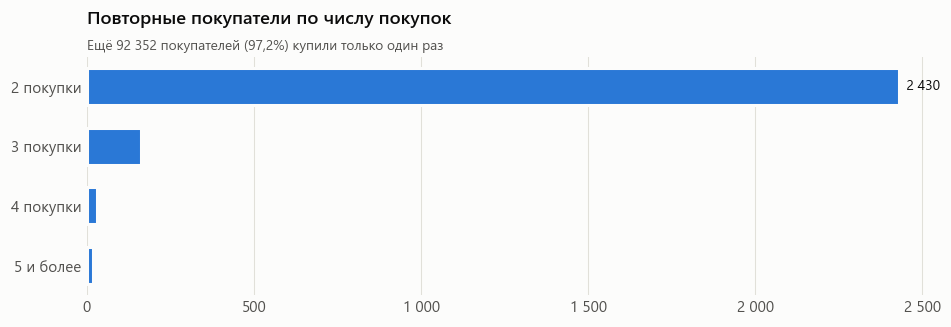

In [4]:
repeat = freq[freq.purchases >= 2]
labels = [f"{p} покупки" if p < 5 else "5 и более" for p in repeat.purchases]
fig, ax = plt.subplots(figsize=(10, 2.8))
st.hbar(ax, labels, repeat.customers, fmt=st.num)
st.count_axis(ax, "x")
one = freq[freq.purchases == 1].iloc[0]
st.titles(ax, "Повторные покупатели по числу покупок",
          f"Ещё {st.num(one.customers)} покупателей ({st.pct(one.customer_share, 1)}) купили только один раз")
st.save(fig, "olist_customers_01_purchases_per_customer")
plt.show()

**Формула**

$$\mathrm{RPR} = \frac{\left|\{\, c \in C : P_c \ge 2 \,\}\right|}{|C|}, \qquad \text{доля выручки} = \frac{\sum_{c:\,P_c \ge 2} R_c}{\sum_{c \in C} R_c}$$

где $C$ — покупатели с валидными заказами, $P_c$ — число разных моментов покупки покупателя $c$, $R_c$ — его выручка.

**Пример расчёта**

$$\mathrm{RPR} = \frac{2\,638}{94\,990} \approx 0{,}0278, \qquad \text{доля выручки} = \frac{697\,761{,}81}{13\,494\,400{,}74} \approx 0{,}0517$$

**Вывод.**
- **RPR = 2,8%**: из 94 990 покупателей только 2 638 сделали вторую покупку. 97,2% купили один раз.
- Повторные покупатели дают лишь **5,2% выручки**. Бизнес Olist за этот период — это почти целиком привлечение новых покупателей.
- Если считать повторные покупки по заказам, а не по моментам покупки, получится 3,0%: разбитые по продавцам
  чекауты завышают метрику примерно на 9%.
- Для сравнения: у типичного e-commerce RPR 20–30%. Низкое значение отчасти объясняется устройством Olist: это
  маркетплейс-агрегатор, покупатель часто не знает, что снова покупает через Olist.

## RFM-сегментация

**Вопрос:** на какие группы делятся покупатели по давности, частоте и сумме покупок?
**Метрики:**
- **R** (recency) — дней от последней покупки до 2018-09-04, квинтили, 5 = самые свежие;
- **F** (frequency) — число покупок, шкала 1…5+ (квинтили не работают: у 97% F = 1);
- **M** (monetary) — выручка покупателя, квинтили, 5 = самые крупные.

Правила сегментов описаны в [gold.md](../../docs/architecture/gold.md), раздел «RFM».

In [5]:
segments = q("""
    select segment,
           count(*)               as customers,
           sum(monetary)          as revenue,
           avg(monetary)          as avg_revenue,
           avg(recency_days)      as avg_recency_days,
           avg(frequency)         as avg_frequency
    from gold_rfm_segments
    group by 1
    order by revenue desc
""")
names = {
    "champions": "Чемпионы", "loyal": "Лояльные", "at_risk": "Под угрозой ухода",
    "new_high_value": "Новые крупные", "new": "Новые", "needs_attention": "Требуют внимания",
    "hibernating_high_value": "Спящие крупные", "hibernating": "Спящие",
}
segments.insert(1, "сегмент", segments.segment.map(names))
segments["customer_share"] = segments.customers / segments.customers.sum()
segments["revenue_share"] = segments.revenue / segments.revenue.sum()
st.as_pct(segments, ["customer_share", "revenue_share"])

,segment,сегмент,customers,revenue,avg_revenue,avg_recency_days,avg_frequency,customer_share,revenue_share
0,new_high_value,Новые крупные,14773,"3 958 123,32","267,93","97,85","1,00","15,6%","29,3%"
1,hibernating_high_value,Спящие крупные,14079,"3 911 771,36","277,84","401,56","1,00","14,8%","29,0%"
2,needs_attention,Требуют внимания,18447,"2 415 525,80","130,94","226,25","1,00","19,4%","17,9%"
3,hibernating,Спящие,23003,"1 284 195,42","55,83","401,83","1,00","24,2%","9,5%"
4,new,Новые,22050,"1 227 023,03","55,65","95,54","1,00","23,2%","9,1%"
5,champions,Чемпионы,1173,"321 566,61","274,14","94,70","2,15","1,2%","2,4%"
6,at_risk,Под угрозой ухода,914,"235 144,02","257,27","387,15","2,08","1,0%","1,7%"
7,loyal,Лояльные,551,"141 051,18","255,99","223,43","2,09","0,6%","1,0%"


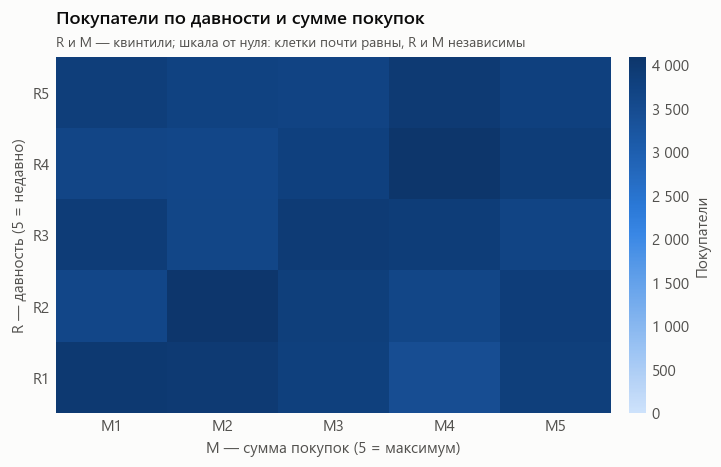

In [6]:
rm = q("""
    select r_score, m_score, count(*) as customers
    from gold_rfm_segments
    group by 1, 2
""").pivot(index="r_score", columns="m_score", values="customers").sort_index(ascending=False)

fig, ax = plt.subplots(figsize=(7, 4.2))
im = ax.imshow(rm.values, cmap=st.SEQUENTIAL, aspect="auto", vmin=0)
ax.set_xticks(range(5), [f"M{m}" for m in rm.columns])
ax.set_yticks(range(5), [f"R{r}" for r in rm.index])
ax.set_xlabel("M — сумма покупок (5 = максимум)")
ax.set_ylabel("R — давность (5 = недавно)")
ax.grid(False)
ax.spines["bottom"].set_visible(False)
cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.03)
cbar.outline.set_visible(False)
cbar.set_label("Покупатели", color=st.INK_2)
cbar.formatter = plt.FuncFormatter(lambda v, _: st.num(v))
cbar.update_ticks()
st.titles(ax, "Покупатели по давности и сумме покупок", "R и M — квинтили; шкала от нуля: клетки почти равны, R и M независимы")
st.save(fig, "olist_customers_02_rfm_r_by_m")
plt.show()

In [7]:
corr = q("select corr(recency_days, monetary) as r from gold_rfm_segments")
corr

,r
0,"0,00"


**Формула**

$$\mathrm{rec}_c = t_{\mathrm{ref}} - t^{\mathrm{last}}_c, \qquad R_c = 6 - \mathrm{ntile}_5(\mathrm{rec}_c), \qquad F_c = \min(P_c,\, 5), \qquad M_c = \mathrm{ntile}_5(m_c)$$

где $t_{\mathrm{ref}}$ — дата отсчёта (4 сентября 2018), $t^{\mathrm{last}}_c$ — дата последней покупки,
$\mathrm{ntile}_5$ — номер квинтиля (1…5) по возрастанию, $m_c$ — сумма покупок покупателя.

**Пример расчёта**

Границы квинтилей давности: 99, 183, 274 и 389 дней; суммы: 39,9; 69,9; 109,9 и 179,9.
Покупатель, который один раз купил на 200 за 50 дней до даты отсчёта:

$$\mathrm{rec} = 50 < 99 \Rightarrow R = 5, \qquad F = \min(1, 5) = 1, \qquad m = 200 > 179{,}9 \Rightarrow M = 5$$

Код $R F M = 5\,1\,5$ — сегмент «Новые крупные».

**Вывод.**
- Крупнейшие сегменты — одноразовые покупатели: **Спящие (24%)**, **Новые (23%)**, **Требуют внимания (19%)**,
  **Новые крупные (16%)** и **Спящие крупные (15%)**.
- Сегменты с повторными покупками малы: **Чемпионы — 1 173**, **Лояльные — 551**, **Под угрозой ухода — 914**
  (всего 2,8% покупателей).
- Давность и сумма покупок не связаны (клетки матрицы R × M почти одинаковы, корреляция около нуля):
  крупный покупатель не возвращается чаще мелкого.
- Практический вывод: RFM здесь в основном делит покупателей по давности и сумме **одной** покупки.
  Для реактивации самые ценные — **Новые крупные** (недавно, дорого) и **Спящие крупные** (давно, дорого).

## Когортная матрица удержания

**Вопрос:** какая доля покупателей каждой месячной когорты возвращается в следующие месяцы?
**Метрика:** когорта = месяц первой покупки; удержание в месяц k = покупатели когорты с покупкой в месяце k / размер когорты.

In [8]:
cohorts = q("""
    with purchases as (
        select customer_key, date_trunc('month', purchase_ts) as month
        from fact_orders
        where is_valid_order
        group by 1, 2
    ),
    first as (
        select customer_key, min(month) as cohort
        from purchases
        group by 1
    ),
    activity as (
        select f.cohort,
               datediff('month', f.cohort, p.month) as month_number,
               count(distinct p.customer_key)       as customers
        from purchases p
        join first f using (customer_key)
        group by 1, 2
    )
    select a.cohort, s.customers as cohort_size, a.month_number, a.customers,
           a.customers / s.customers as retention
    from activity a
    join activity s on s.cohort = a.cohort and s.month_number = 0
    where a.cohort between date '2017-01-01' and date '2018-07-01'
      and a.cohort + to_months(a.month_number) <= date '2018-08-01'
    order by 1, 3
""")
matrix = cohorts.pivot(index="cohort", columns="month_number", values="retention")
matrix.index = matrix.index.strftime("%Y-%m")
sizes = cohorts.drop_duplicates("cohort").set_index(cohorts.drop_duplicates("cohort").cohort.dt.strftime("%Y-%m")).cohort_size
matrix.loc[:, 1:12].apply(lambda col: col.map(lambda v: st.pct(v, 2) if v == v else ""))

month_number,1,2,3,4,5,6,7,8,9,10,11,12
cohort,,,,,,,,,,,,
2017-01,"0,40%","0,27%","0,13%","0,40%","0,13%","0,40%","0,13%","0,13%",,"0,40%","0,13%","0,66%"
2017-02,"0,24%","0,30%","0,12%","0,41%","0,12%","0,24%","0,18%","0,12%","0,18%","0,12%","0,30%","0,12%"
2017-03,"0,51%","0,35%","0,39%","0,35%","0,16%","0,16%","0,31%","0,35%","0,08%","0,39%","0,12%","0,23%"
2017-04,"0,60%","0,22%","0,17%","0,30%","0,26%","0,34%","0,30%","0,30%","0,17%","0,26%","0,09%","0,09%"
2017-05,"0,48%","0,48%","0,40%","0,31%","0,34%","0,42%","0,14%","0,25%","0,25%","0,25%","0,34%","0,25%"
2017-06,"0,45%","0,35%","0,39%","0,26%","0,39%","0,35%","0,23%","0,13%","0,23%","0,32%","0,32%","0,16%"
2017-07,"0,52%","0,34%","0,24%","0,29%","0,21%","0,31%","0,10%","0,18%","0,26%","0,21%","0,29%","0,13%"
2017-08,"0,68%","0,34%","0,27%","0,36%","0,53%","0,29%","0,27%","0,15%","0,15%","0,24%","0,19%","0,12%"
2017-09,"0,69%","0,54%","0,29%","0,44%","0,22%","0,22%","0,25%","0,29%","0,17%","0,27%","0,07%",


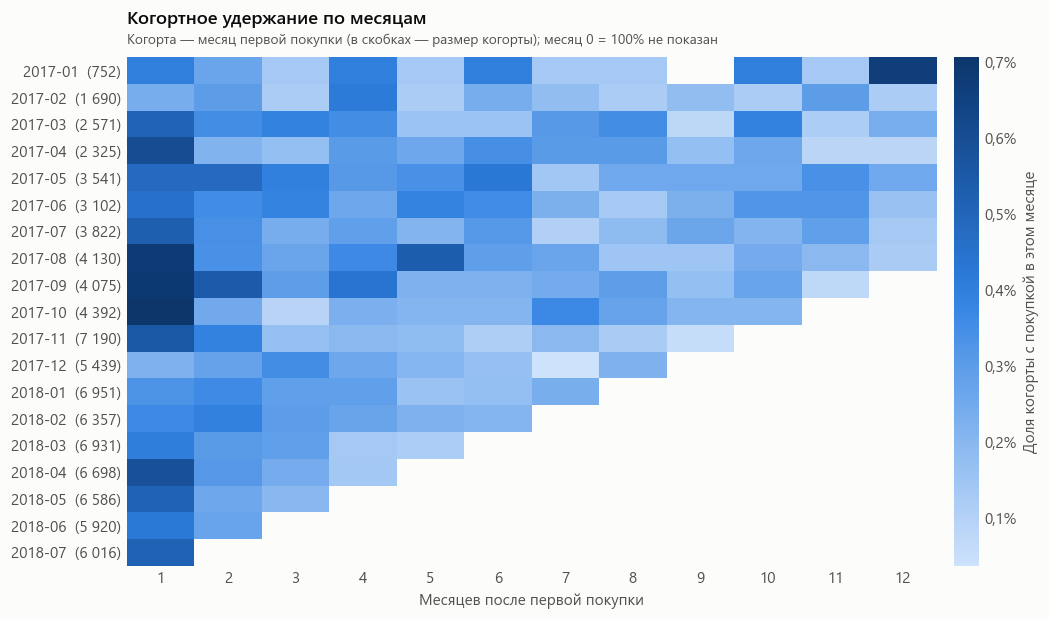

In [9]:
view = matrix.loc[:, 1:12]
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(view.values * 100, cmap=st.SEQUENTIAL, aspect="auto")
ax.set_xticks(range(view.shape[1]), view.columns)
ax.set_yticks(range(len(view)), [f"{c}  ({st.num(sizes[c])})" for c in view.index])
ax.set_xlabel("Месяцев после первой покупки")
ax.grid(False)
ax.spines["bottom"].set_visible(False)
cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, format=plt.FuncFormatter(lambda v, _: f"{st.num(v, 1)}%"))
cbar.outline.set_visible(False)
cbar.set_label("Доля когорты с покупкой в этом месяце", color=st.INK_2)
st.titles(ax, "Когортное удержание по месяцам", "Когорта — месяц первой покупки (в скобках — размер когорты); месяц 0 = 100% не показан")
st.save(fig, "olist_customers_03_cohort_retention")
plt.show()

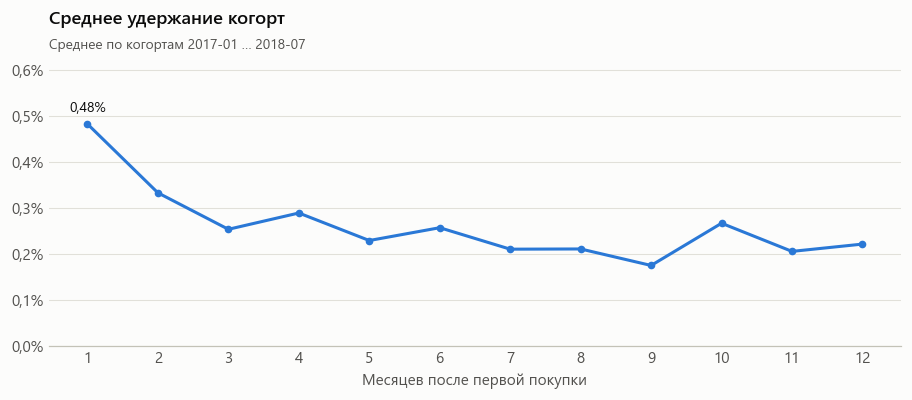

month_number,1,2,3,4,5,6,7,8,9,10,11,12
средняя доля,"0,48%","0,33%","0,25%","0,29%","0,23%","0,26%","0,21%","0,21%","0,17%","0,27%","0,21%","0,22%"


In [10]:
curve = view.mean().rename("средняя доля")
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(curve.index, curve.values, color=st.BLUE, marker="o", markersize=4)
st.percent_axis(ax, decimals=1)
ax.set_ylim(0, curve.max() * 1.3)
ax.set_xticks(curve.index)
ax.set_xlabel("Месяцев после первой покупки")
st.label_point(ax, curve.index[0], curve.iloc[0], st.pct(curve.iloc[0], 2))
st.titles(ax, "Среднее удержание когорт", "Среднее по когортам 2017-01 … 2018-07")
st.save(fig, "olist_customers_04_retention_curve")
plt.show()
st.as_pct(curve.to_frame(), ["средняя доля"], 2).T

**Формула**

$$r_{c,k} = \frac{|U_{c,k}|}{|U_{c,0}|}$$

где $U_{c,0}$ — покупатели, впервые купившие в месяце $c$ (когорта), $U_{c,k}$ — покупатели этой когорты
с покупкой в месяце $c + k$.

**Пример расчёта** (когорта августа 2017, первый месяц)

$$r_{\text{2017-08},\,1} = \frac{28}{4\,130} \approx 0{,}0068 \;(0{,}68\%)$$

**Вывод.**
- Удержание **крайне низкое**: в первый месяц после покупки возвращаются в среднем **~0,5%** когорты,
  дальше — 0,2–0,4% в месяц. За полгода суммарно возвращается около 1,5% когорты.
- Кривая быстро выходит на плато и не падает до нуля: небольшое ядро покупателей продолжает покупать
  месяцами, но новых возвращающихся почти нет.
- Лучшее удержание первого месяца — у когорт августа–октября 2017 (0,7%); когорты после Чёрной пятницы
  (декабрь 2017 – февраль 2018) удерживаются хуже: акция привела разовых покупателей.
- Значимых различий между когортами нет — удержание не улучшалось со временем.

## Ценность покупателя (CLV) за наблюдаемый период

**Вопрос:** сколько выручки приносит покупатель за 30, 90, 180 и 365 дней после первой покупки?
**Метрика:** средняя выручка покупателя за N дней от первой покупки. Чтобы сравнение было честным,
для каждого горизонта берутся только покупатели, у которых в данных есть полные N дней.
Это **исторический** CLV по выручке, без маржи и без прогноза.

In [11]:
clv = q("""
    with o as (
        select customer_key, purchase_ts, items_value
        from fact_orders
        where is_valid_order
    ),
    f as (select customer_key, min(purchase_ts) as first_ts from o group by 1),
    data_end as (select max(purchase_ts) as end_ts from o),
    horizons as (select * from (values (30), (90), (180), (365)) t(days))
    select h.days,
           count(distinct f.customer_key)                                         as customers,
           sum(o.items_value) / count(distinct f.customer_key)                    as clv,
           sum(case when o.purchase_ts = f.first_ts then o.items_value end)
               / count(distinct f.customer_key)                                   as first_purchase_value
    from f
    cross join data_end
    cross join horizons h
    join o on o.customer_key = f.customer_key
          and o.purchase_ts < f.first_ts + to_days(h.days)
    where f.first_ts + to_days(h.days) <= data_end.end_ts
    group by 1
    order by 1
""")
clv["repeat_uplift"] = clv.clv / clv.first_purchase_value - 1
st.as_pct(clv, ["repeat_uplift"])

,days,customers,clv,first_purchase_value,repeat_uplift
0,30,89686,"140,25","138,51","1,3%"
1,90,77568,"141,09","138,33","2,0%"
2,180,58101,"140,47","136,62","2,8%"
3,365,22483,"144,23","138,23","4,3%"


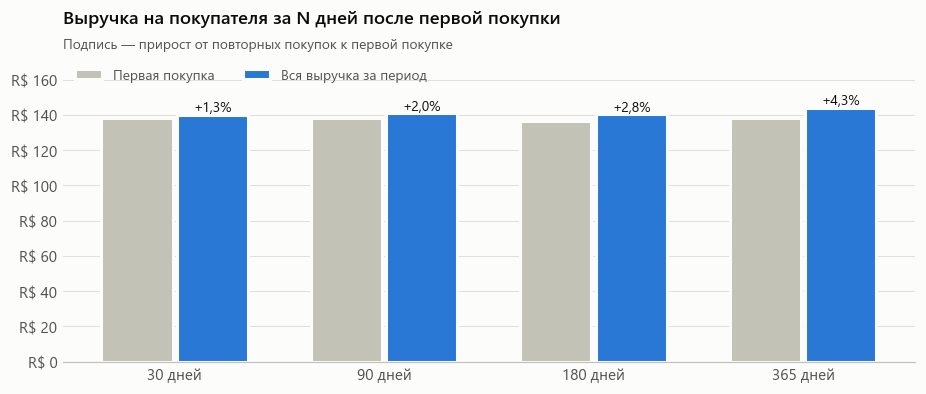

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(clv))
ax.bar(x - 0.18, clv.first_purchase_value, width=0.34, color=st.CONTEXT, label="Первая покупка", edgecolor=st.SURFACE, linewidth=2)
ax.bar(x + 0.18, clv.clv, width=0.34, color=st.BLUE, label="Вся выручка за период", edgecolor=st.SURFACE, linewidth=2)
for i, r in clv.iterrows():
    ax.text(i + 0.18, r.clv, f"+{st.pct(r.repeat_uplift, 1)}", ha="center", va="bottom", fontsize=9, color=st.INK)
ax.set_xticks(x, [f"{d} дней" for d in clv.days])
st.money_axis(ax, full=True)
ax.set_ylim(0, clv.clv.max() * 1.2)
ax.legend(loc="upper left", ncols=2)
st.titles(ax, "Выручка на покупателя за N дней после первой покупки", "Подпись — прирост от повторных покупок к первой покупке")
st.save(fig, "olist_customers_05_clv_horizons")
plt.show()

In [13]:
clv_region = q("""
    with o as (select customer_key, purchase_ts, items_value from fact_orders where is_valid_order),
    f as (select customer_key, min(purchase_ts) as first_ts from o group by 1),
    data_end as (select max(purchase_ts) as end_ts from o)
    select d.current_region as region,
           count(distinct f.customer_key)                           as customers,
           sum(o.items_value) / count(distinct f.customer_key)      as clv_180
    from f
    cross join data_end
    join o on o.customer_key = f.customer_key and o.purchase_ts < f.first_ts + interval 180 day
    join dim_customer d on d.customer_key = f.customer_key
    where f.first_ts + interval 180 day <= data_end.end_ts
    group by 1
    order by clv_180 desc
""")
clv_region

,region,customers,clv_180
0,Norte,1195,"182,51"
1,Nordeste,5756,"165,60"
2,Centro-Oeste,3432,"153,89"
3,Sul,8588,"137,12"
4,Sudeste,39130,"135,04"


**Формула**

$$\mathrm{CLV}_H = \frac{1}{|C_H|}\sum_{c \in C_H}\ \sum_{o:\ t_o < t^{\mathrm{first}}_c + H} R_o, \qquad \mathrm{uplift}_H = \frac{\mathrm{CLV}_H}{\bar{R}^{\mathrm{first}}_H} - 1$$

где $H$ — горизонт в днях, $C_H$ — покупатели, у которых в данных есть полные $H$ дней после первой покупки,
$\bar{R}^{\mathrm{first}}_H$ — средняя выручка их первой покупки.

**Пример расчёта** ($H = 365$ дней)

$$|C_H| = 22\,483, \qquad \mathrm{CLV}_{365} = \frac{3\,242\,644{,}13}{22\,483} \approx 144{,}23, \qquad \bar{R}^{\mathrm{first}}_{365} = \frac{3\,107\,837{,}46}{22\,483} \approx 138{,}23$$

$$\mathrm{uplift}_{365} = \frac{144{,}23}{138{,}23} - 1 \approx 0{,}043 \;(+4{,}3\%)$$

**Вывод.**
- **CLV за 365 дней ≈ R&#36; 144**, при этом первая покупка тех же покупателей — около R&#36; 138.
  Повторные покупки добавляют к первой лишь **1–4%** в зависимости от горизонта.
- CLV почти не растёт с горизонтом: R&#36; 140 за 30 дней и R&#36; 144 за год. Почти вся ценность покупателя —
  это его первая покупка.
- По регионам CLV повторяет средний чек: выше всего на Севере и Северо-Востоке, ниже всего на Юго-Востоке
  (см. ноутбук продаж, раздел «Продажи по регионам»).
- Следствие для маркетинга: допустимая стоимость привлечения покупателя ограничена маржой **одной** покупки.
  Рост CLV возможен только через удержание, которого сейчас практически нет.

## Частота повторных покупок

**Вопрос:** через сколько дней покупатели возвращаются и что влияет на возврат?
**Метрики:** интервал между соседними покупками; доля повторных покупателей по категории первой покупки,
оценке первого заказа и опозданию доставки.

In [14]:
gaps = q("""
    with p as (
        select customer_key, customer_purchase_seq as seq, min(purchase_ts) as ts
        from fact_orders
        where is_valid_order
        group by 1, 2
    )
    select a.customer_key, a.seq, datediff('day', a.ts, b.ts) as gap_days
    from p a
    join p b on b.customer_key = a.customer_key and b.seq = a.seq + 1
""")
gap_stats = pd.DataFrame({
    "интервалов": [len(gaps)],
    "медиана, дней": [gaps.gap_days.median()],
    "среднее, дней": [gaps.gap_days.mean()],
    "в тот же день": [(gaps.gap_days == 0).mean()],
    "в течение 30 дней": [(gaps.gap_days <= 30).mean()],
    "позже 180 дней": [(gaps.gap_days > 180).mean()],
})
st.as_pct(gap_stats, ["в тот же день", "в течение 30 дней", "позже 180 дней"])

,интервалов,"медиана, дней","среднее, дней",в тот же день,в течение 30 дней,позже 180 дней
0,2934,"40,00","86,50","22,1%","45,8%","17,8%"


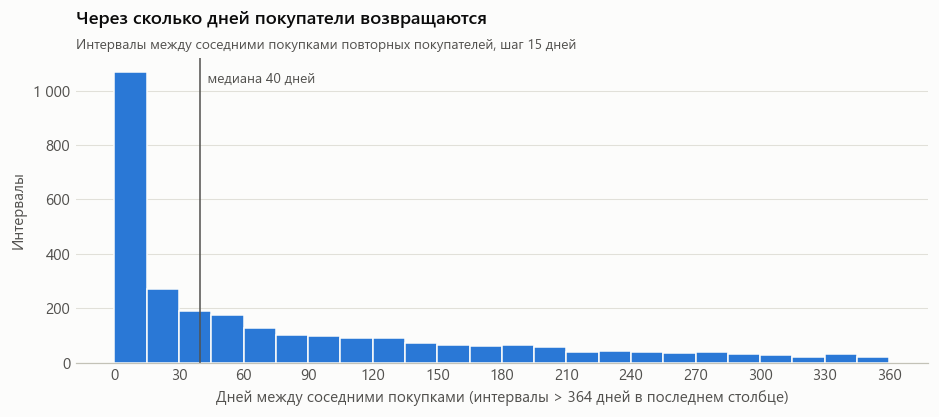

In [15]:
fig, ax = plt.subplots(figsize=(10, 3.6))
bins = np.arange(0, 375, 15)
ax.hist(gaps.gap_days.clip(upper=364), bins=bins, color=st.BLUE, edgecolor=st.SURFACE, linewidth=1)
med = gaps.gap_days.median()
ax.axvline(med, color=st.INK_2, linewidth=1)
ax.text(med, ax.get_ylim()[1] * 0.95, f"  медиана {st.num(med)} дней", fontsize=9, color=st.INK_2, va="top")
ax.set_xlabel("Дней между соседними покупками (интервалы > 364 дней в последнем столбце)")
ax.set_ylabel("Интервалы")
st.count_axis(ax)
ax.set_xticks(range(0, 375, 30))
st.titles(ax, "Через сколько дней покупатели возвращаются", "Интервалы между соседними покупками повторных покупателей, шаг 15 дней")
st.save(fig, "olist_customers_06_days_between_purchases")
plt.show()

In [16]:
by_category = q("""
    with first_items as (
        select i.customer_key, p.category_en,
               row_number() over (partition by i.customer_key order by i.price desc, i.order_item_id) as rn
        from fact_order_items i
        join fact_orders o using (order_id)
        join dim_product p using (product_key)
        where o.is_valid_order and o.customer_order_seq = 1
    )
    select category_en,
           count(*)                         as customers,
           avg(d.is_repeat_customer::int)   as rpr
    from first_items
    join dim_customer d using (customer_key)
    where rn = 1 and category_en <> 'unknown'
    group by 1
    having count(*) >= 1000
    order by rpr desc
""")
st.as_pct(by_category, ["rpr"], 2)

,category_en,customers,rpr
0,fashion_bags_accessories,1727,"5,21%"
1,bed_bath_table,8859,"4,11%"
2,furniture_decor,6012,"4,11%"
3,sports_leisure,7324,"3,51%"
4,pet_shop,1647,"2,85%"
5,garden_tools,3369,"2,82%"
6,computers_accessories,6412,"2,68%"
7,perfumery,3044,"2,63%"
8,housewares,5597,"2,57%"
9,health_beauty,8502,"2,54%"


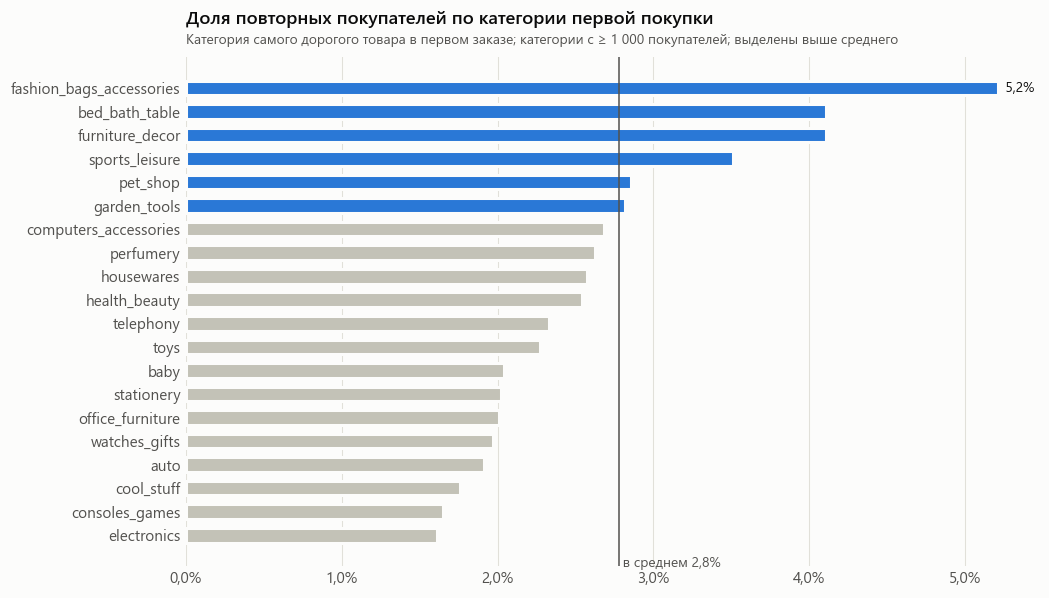

In [17]:
overall = rpr.rpr[0]
fig, ax = plt.subplots(figsize=(10, 6))
st.hbar(ax, by_category.category_en, by_category.rpr,
        highlight=by_category.category_en[by_category.rpr > overall], fmt=lambda v: st.pct(v, 1))
ax.axvline(overall, color=st.INK_2, linewidth=1)
ax.text(overall, -0.9, f" в среднем {st.pct(overall, 1)}", fontsize=9, color=st.INK_2, va="top")
st.percent_axis(ax, "x", decimals=1)
st.titles(ax, "Доля повторных покупателей по категории первой покупки",
          "Категория самого дорогого товара в первом заказе; категории с ≥ 1 000 покупателей; выделены выше среднего")
st.save(fig, "olist_customers_07_rpr_by_first_category")
plt.show()

In [18]:
experience = q("""
    with first as (
        select customer_key, review_score, is_late
        from fact_orders
        where is_valid_order and customer_order_seq = 1
    )
    select 'оценка первого заказа' as factor, review_score::varchar as value,
           count(*) as customers, avg(d.is_repeat_customer::int) as rpr
    from first join dim_customer d using (customer_key)
    where review_score is not null
    group by 1, 2
    union all
    select 'первый заказ опоздал', case when is_late then 'да' else 'нет' end,
           count(*), avg(d.is_repeat_customer::int)
    from first join dim_customer d using (customer_key)
    where is_late is not null
    group by 1, 2
    order by 1, 2
""")
st.as_pct(experience, ["rpr"], 2)

,factor,value,customers,rpr
0,оценка первого заказа,1,10168,"2,59%"
1,оценка первого заказа,2,2953,"2,37%"
2,оценка первого заказа,3,7792,"2,71%"
3,оценка первого заказа,4,18461,"2,57%"
4,оценка первого заказа,5,54914,"2,91%"
5,первый заказ опоздал,да,6348,"2,33%"
6,первый заказ опоздал,нет,86945,"2,80%"


**Формула**

$$\Delta_{c,k} = t_{c,k+1} - t_{c,k}, \qquad \mathrm{RPR}_g = \frac{\left|\{\, c \in C_g : P_c \ge 2 \,\}\right|}{|C_g|}$$

где $t_{c,k}$ — момент $k$-й покупки покупателя $c$, $C_g$ — покупатели, у которых самый дорогой товар
первого заказа относится к категории $g$.

**Пример расчёта**

Интервалов: 2 934, медиана — 40 дней, в тот же день: $647 / 2\,934 \approx 0{,}22$.

$$\mathrm{RPR}_{\text{fashion}} = \frac{90}{1\,727} \approx 0{,}052, \qquad \mathrm{RPR}_{\text{electronics}} = \frac{40}{2\,484} \approx 0{,}016, \qquad \frac{0{,}052}{0{,}016} \approx 3{,}2$$

**Вывод.**
- Медианный интервал между покупками — **40 дней**, но распределение очень широкое:
  **22% повторных покупок — в тот же день** (докупка забытого товара), 46% — в течение месяца,
  остальные растянуты на год.
- Возврат сильнее всего зависит от **категории первой покупки**: fashion_bags_accessories (5,2%),
  bed_bath_table и furniture_decor (4,1%), sports_leisure (3,5%) — в 1,5–2 раза выше среднего.
  Ниже всего — electronics, consoles_games, cool_stuff, auto, watches_gifts (1,6–2,0%): разовые и подарочные покупки.
- Опыт первого заказа влияет слабо: при оценке 5 возвращаются 2,9%, при оценке 1–2 — 2,4–2,6%;
  после опоздания доставки — 2,3% против 2,8%. Направление ожидаемое, но эффект меньше, чем у категории.
- Программу удержания стоит начинать с покупателей «домашних» категорий (текстиль, декор, аксессуары) —
  у них уже есть естественная повторяемость.

## Сегменты покупателей с наибольшей выручкой

**Вопрос:** какие сегменты приносят основную выручку и насколько их вклад отличается от их численности?
**Метрики:** доля покупателей и доля выручки по RFM-сегментам.

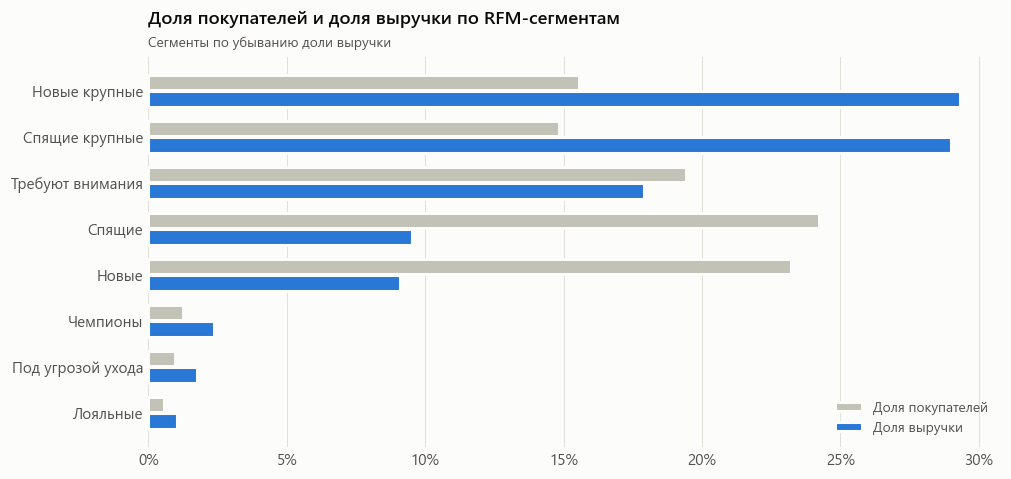

,сегмент,customers,customer_share,revenue,revenue_share,avg_revenue
0,Новые крупные,14773,"15,6%","3 958 123,32","29,3%","267,93"
1,Спящие крупные,14079,"14,8%","3 911 771,36","29,0%","277,84"
2,Требуют внимания,18447,"19,4%","2 415 525,80","17,9%","130,94"
3,Спящие,23003,"24,2%","1 284 195,42","9,5%","55,83"
4,Новые,22050,"23,2%","1 227 023,03","9,1%","55,65"
5,Чемпионы,1173,"1,2%","321 566,61","2,4%","274,14"
6,Под угрозой ухода,914,"1,0%","235 144,02","1,7%","257,27"
7,Лояльные,551,"0,6%","141 051,18","1,0%","255,99"


In [19]:
seg = segments.sort_values("revenue_share", ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(seg))[::-1]
ax.barh(y + 0.18, seg.customer_share, height=0.34, color=st.CONTEXT, label="Доля покупателей", edgecolor=st.SURFACE, linewidth=2)
ax.barh(y - 0.18, seg.revenue_share, height=0.34, color=st.BLUE, label="Доля выручки", edgecolor=st.SURFACE, linewidth=2)
ax.set_yticks(y, seg["сегмент"])
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.spines["bottom"].set_visible(False)
st.percent_axis(ax, "x")
ax.legend(loc="lower right")
st.titles(ax, "Доля покупателей и доля выручки по RFM-сегментам", "Сегменты по убыванию доли выручки")
st.save(fig, "olist_customers_08_segments_revenue")
plt.show()
st.as_pct(seg[["сегмент", "customers", "customer_share", "revenue", "revenue_share", "avg_revenue"]], ["customer_share", "revenue_share"])

**Формула**

$$\mathrm{share}^{\mathrm{cust}}_g = \frac{n_g}{N}, \qquad \mathrm{share}^{\mathrm{rev}}_g = \frac{R_g}{R}, \qquad I_g = \frac{\mathrm{share}^{\mathrm{rev}}_g}{\mathrm{share}^{\mathrm{cust}}_g}$$

где $n_g$ и $R_g$ — покупатели и выручка сегмента $g$; индекс $I_g > 1$ значит, что сегмент приносит
больше выручки, чем его доля в базе.

**Пример расчёта** (Новые крупные + Спящие крупные)

$$\mathrm{share}^{\mathrm{cust}} = \frac{14\,773 + 14\,079}{94\,990} \approx 0{,}304, \qquad \mathrm{share}^{\mathrm{rev}} = \frac{7\,869\,894{,}68}{13\,494\,400{,}74} \approx 0{,}583, \qquad I \approx 1{,}92$$

**Вывод.**
- **Новые крупные** и **Спящие крупные** — 30% покупателей и **58% выручки**: выручку Olist делают
  покупатели с одной дорогой покупкой. **Требуют внимания** добавляют ещё 18%.
- **Спящие** и **Новые** (мелкие разовые) — почти половина покупателей (47%), но лишь 19% выручки.
- **Чемпионы + Лояльные + Под угрозой ухода** — 2,8% покупателей и около 5% выручки; их средняя выручка
  выше среднего, но сегменты слишком малы, чтобы влиять на итог.
- Приоритеты:
  1. **Новые крупные** — главная цель удержания: недавно купили дорого, ещё не ушли.
  2. **Спящие крупные** — реактивация (напоминания, персональные предложения в их категории).
  3. **Под угрозой ухода** — уже покупали повторно; вернуть их дешевле, чем привлечь новых.

## Итоги

| Вопрос | Ответ |
|---|---|
| Повторные покупки | RPR 2,8%; повторные покупатели дают 5,2% выручки |
| RFM | 97% покупателей — разовые; R и M независимы; ценные сегменты — Новые крупные и Спящие крупные |
| Удержание когорт | ~0,5% в первый месяц, 0,2–0,4% дальше; не улучшается со временем |
| CLV | ≈ R&#36; 144 за год, всего на 1–4% больше первой покупки |
| Частота | медиана 40 дней, 22% — в тот же день; возврат зависит от категории первой покупки |
| Сегменты с наибольшей выручкой | крупные разовые покупатели: 30% базы, 58% выручки |

**Главный вывод:** Olist растёт только за счёт новых покупателей. Самый большой резерв — удержание покупателей
дорогих разовых покупок и «домашних» категорий, где повторяемость уже выше среднего.